In [18]:
pip install pandas numpy matplotlib seaborn scikit-learn xgboost streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
# ============================================================
# LANGKAH 1: LOAD & PEMAHAMAN DATASET
# ============================================================
import pandas as pd
import numpy as np

# 1.1 Import dataset
df = pd.read_csv("D:\Klasifikasi Data Menggunakan XGBoost\ALma_Test1_KlasifikasiXGBoost.csv")

# 1.2 Tampilkan struktur data
print("=" * 60)
print("STRUKTUR DATASET")
print("=" * 60)
print(f"Jumlah baris  : {df.shape[0]}")
print(f"Jumlah kolom  : {df.shape[1]}")
print(f"\nTipe data per kolom:\n{df.dtypes}")
print(f"\nRingkasan statistik:\n{df.describe().round(2)}")

# 1.3 Cek beberapa baris pertama
print(f"\n5 baris pertama:\n{df.head()}")

# 1.4 Tentukan fitur (X) dan target (y)
# Target klasifikasi: apakah hari hujan signifikan (>= 5 mm)?
df['time'] = pd.to_datetime(df['time'])
df['month'] = df['time'].dt.month
df['is_rainy'] = (df['rain_sum'] >= 5.0).astype(int)

# Fitur — BUANG rain_sum & precipitation_* untuk hindari data leakage
fitur = [
    'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
    'wind_speed_10m_max', 'wind_gusts_10m_max',
    'wind_direction_10m_dominant', 'sunshine_duration', 'month'
]
X = df[fitur]
y = df['is_rainy']

print("\n" + "=" * 60)
print("FITUR & TARGET")
print("=" * 60)
print(f"Fitur (X)  : {fitur}")
print(f"Target (y) : 'is_rainy' (0 = tidak hujan, 1 = hujan ≥ 5 mm)")
print(f"\nDistribusi target:")
print(y.value_counts().rename({0: "Tidak Hujan", 1: "Hujan"}))

STRUKTUR DATASET
Jumlah baris  : 1827
Jumlah kolom  : 17

Tipe data per kolom:
time                            object
weather_code                     int64
temperature_2m_mean            float64
temperature_2m_max             float64
temperature_2m_min             float64
precipitation_sum              float64
rain_sum                       float64
precipitation_hours            float64
wind_speed_10m_max             float64
wind_gusts_10m_max             float64
wind_direction_10m_dominant      int64
sunrise                         object
sunset                          object
sunshine_duration              float64
city                            object
latitude                       float64
longitude                      float64
dtype: object

Ringkasan statistik:
       weather_code  temperature_2m_mean  temperature_2m_max  \
count       1827.00              1827.00             1827.00   
mean          34.14                26.26               31.10   
std           29.00           

<>:8: SyntaxWarning: invalid escape sequence '\K'
<>:8: SyntaxWarning: invalid escape sequence '\K'
C:\Users\user\AppData\Local\Temp\ipykernel_10880\641939526.py:8: SyntaxWarning: invalid escape sequence '\K'
  df = pd.read_csv("D:\Klasifikasi Data Menggunakan XGBoost\ALma_Test1_KlasifikasiXGBoost.csv")


In [20]:
df.describe(include='all')

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude,month,is_rainy
count,1827,1827.000000,1827.00000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827,1827,1827.000000,1827,1.827000e+03,1.827000e+03,1827.000000,1827.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1827,1827,NaN,1,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-30T04:55,2021-06-30T18:25,NaN,Kolkata,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN,1827,NaN,NaN,NaN,NaN
mean,2023-12-29 23:59:59.999999744,34.143952,26.26486,31.099234,22.477066,5.429119,5.429119,4.952928,13.782157,30.756596,192.212917,NaN,NaN,33185.460542,NaN,2.257260e+01,8.836390e+01,6.523262,0.314724
min,2021-06-30 00:00:00,0.000000,15.00000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,NaN,NaN,0.000000,NaN,2.257260e+01,8.836390e+01,1.000000,0.000000
25%,2022-09-29 12:00:00,3.000000,23.40000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,NaN,NaN,30684.495000,NaN,2.257260e+01,8.836390e+01,4.000000,0.000000
50%,2023-12-30 00:00:00,51.000000,27.40000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,NaN,NaN,36088.150000,NaN,2.257260e+01,8.836390e+01,7.000000,0.000000
75%,2025-03-30 12:00:00,63.000000,29.10000,33.300000,26.200000,7.350000,7.350000,9.000000,16.600000,36.000000,258.000000,NaN,NaN,39550.540000,NaN,2.257260e+01,8.836390e+01,10.000000,1.000000
max,2026-06-30 00:00:00,65.000000,35.20000,43.900000,30.600000,80.500000,80.500000,24.000000,44.000000,83.900000,360.000000,NaN,NaN,44569.280000,NaN,2.257260e+01,8.836390e+01,12.000000,1.000000


In [21]:
# Cek missing value
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
pd.DataFrame({'Jumlah Missing': missing,'Persentase (%)': missing_pct.round(2)})

,Jumlah Missing,Persentase (%)
time,0,0.0
weather_code,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
precipitation_sum,0,0.0
rain_sum,0,0.0
precipitation_hours,0,0.0
wind_speed_10m_max,0,0.0
wind_gusts_10m_max,0,0.0


In [22]:
import os
os.makedirs("output", exist_ok=True)
print("✅ Folder output/ siap")

✅ Folder output/ siap


MISSING VALUES
temperature_2m_mean            0
temperature_2m_max             0
temperature_2m_min             0
wind_speed_10m_max             0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
sunshine_duration              0
month                          0
is_rainy                       0
dtype: int64

✅ Tidak ada missing value — tidak perlu imputasi.


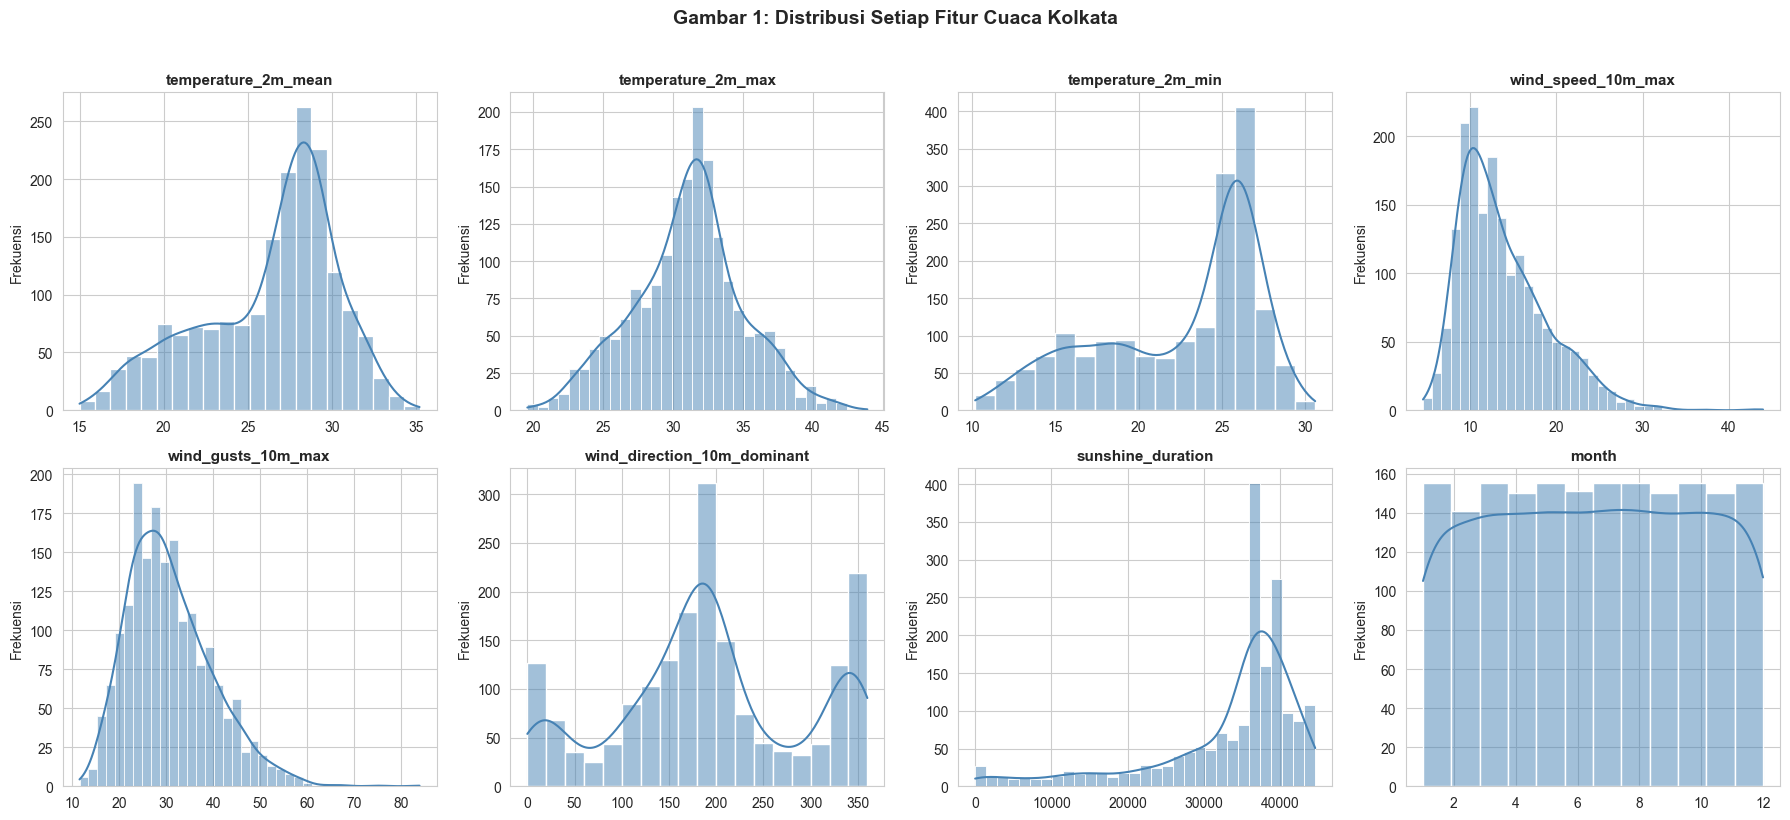

✅ Gambar 1 tersimpan: output/01_distribusi_fitur.png


C:\Users\user\AppData\Local\Temp\ipykernel_10880\141923273.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, ax=axes[0], palette=['#4C9BE8','#E8744C'])
C:\Users\user\AppData\Local\Temp\ipykernel_10880\141923273.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Tidak Hujan\n(<5 mm)", "Hujan\n(≥5 mm)"])


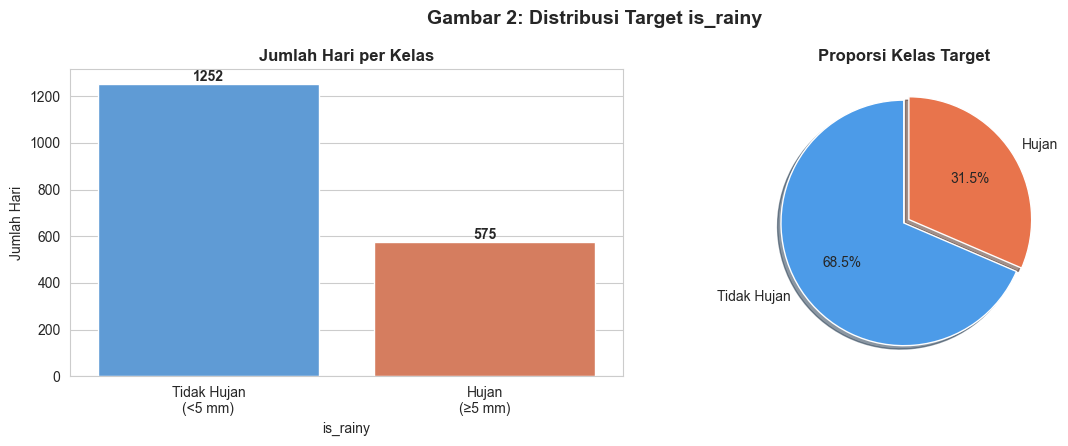

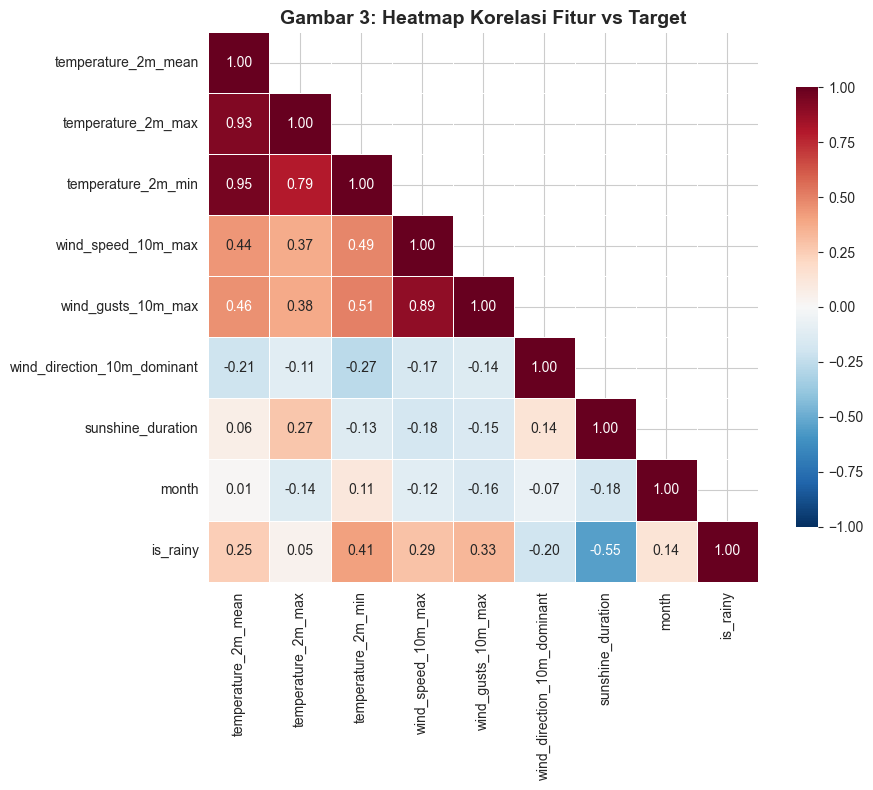

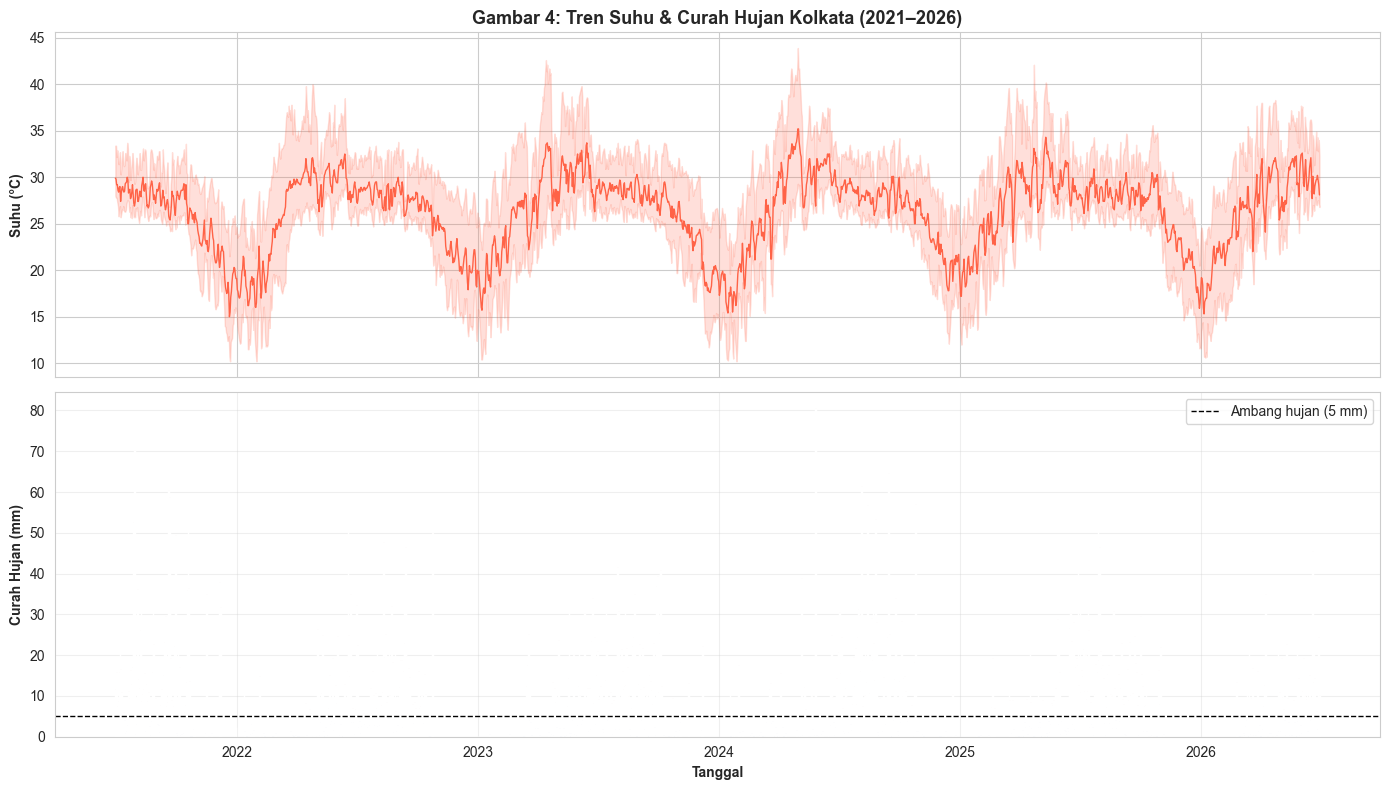


✅ EDA selesai. Gambar 1–4 tersimpan di folder output/.


In [23]:
# ============================================================
# LANGKAH 2: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

# 2.1 Cek missing values
print("=" * 60)
print("MISSING VALUES")
print("=" * 60)
missing = df[fitur + ['is_rainy']].isnull().sum()
print(missing)
if missing.sum() == 0:
    print("\n✅ Tidak ada missing value — tidak perlu imputasi.")
else:
    # Jika ada: isi numerik dengan median, kategorikal dengan modus
    df[fitur] = df[fitur].fillna(df[fitur].median())
    print("\n⚠️ Missing value diisi dengan median.")

# 2.2 Distribusi fitur (histogram)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), fitur):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('Frekuensi')
plt.suptitle("Gambar 1: Distribusi Setiap Fitur Cuaca Kolkata",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("output/01_distribusi_fitur.png", bbox_inches='tight')
plt.show()
print("✅ Gambar 1 tersimpan: output/01_distribusi_fitur.png")

# 2.3 Proporsi kelas target
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x=y, ax=axes[0], palette=['#4C9BE8','#E8744C'])
axes[0].set_xticklabels(["Tidak Hujan\n(<5 mm)", "Hujan\n(≥5 mm)"])
axes[0].set_title("Jumlah Hari per Kelas", fontweight='bold')
axes[0].set_ylabel("Jumlah Hari")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x()+p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontweight='bold')

axes[1].pie(y.value_counts(), labels=["Tidak Hujan","Hujan"],
            autopct='%1.1f%%', colors=['#4C9BE8','#E8744C'],
            startangle=90, explode=(0, 0.05), shadow=True)
axes[1].set_title("Proporsi Kelas Target", fontweight='bold')
plt.suptitle("Gambar 2: Distribusi Target is_rainy",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("output/02_proporsi_kelas.png", bbox_inches='tight')
plt.show()

# 2.4 Heatmap korelasi
plt.figure(figsize=(10, 8))
corr = df[fitur + ['is_rainy']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink":0.8})
plt.title("Gambar 3: Heatmap Korelasi Fitur vs Target",
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("output/03_heatmap_korelasi.png", bbox_inches='tight')
plt.show()

# 2.5 Tren cuaca harian
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df['time'], df['temperature_2m_mean'], color='tomato', lw=1)
axes[0].fill_between(df['time'], df['temperature_2m_min'], df['temperature_2m_max'],
                     color='tomato', alpha=0.2)
axes[0].set_ylabel("Suhu (°C)", fontweight='bold')
axes[0].set_title("Gambar 4: Tren Suhu & Curah Hujan Kolkata (2021–2026)",
                  fontsize=13, fontweight='bold')

rain_colors = ['#4C9BE8' if r < 5 else '#E8744C' for r in df['rain_sum']]
axes[1].bar(df['time'], df['rain_sum'], color=rain_colors, width=1.0)
axes[1].axhline(5, color='black', linestyle='--', lw=1, label='Ambang hujan (5 mm)')
axes[1].set_ylabel("Curah Hujan (mm)", fontweight='bold')
axes[1].set_xlabel("Tanggal", fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("output/04_tren_cuaca.png", bbox_inches='tight')
plt.show()

print("\n✅ EDA selesai. Gambar 1–4 tersimpan di folder output/.")

In [24]:
# ============================================================
# LANGKAH 3: PRA-PEMROSESAN
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 3.1 Cek kolom kategorikal
kategorikal = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("=" * 60)
print("PRA-PEMROSESAN")
print("=" * 60)
if kategorikal:
    print(f"Kolom kategorikal ditemukan: {kategorikal}")
    # Contoh jika ada: X = pd.get_dummies(X, columns=kategorikal, drop_first=True)
else:
    print("✅ Tidak ada kolom kategorikal — encoding tidak diperlukan.")

# 3.2 Split data 80% train / 20% test (stratify agar proporsi kelas seimbang)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nUkuran data latih : {X_train.shape}")
print(f"Ukuran data uji   : {X_test.shape}")

# 3.3 Scaling — FIT hanya di train, TRANSFORM di test (anti-leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"\n✅ Scaling selesai. Data leakage dicegah:")
print(f"   - StandardScaler.fit() hanya pada data latih")
print(f"   - StandardScaler.transform() pada data uji")
print(f"   - Split dilakukan SEBELUM scaling")

PRA-PEMROSESAN
✅ Tidak ada kolom kategorikal — encoding tidak diperlukan.

Ukuran data latih : (1461, 8)
Ukuran data uji   : (366, 8)

✅ Scaling selesai. Data leakage dicegah:
   - StandardScaler.fit() hanya pada data latih
   - StandardScaler.transform() pada data uji
   - Split dilakukan SEBELUM scaling


In [25]:
# ============================================================
# LANGKAH 4: TRAINING MODEL XGBOOST
# ============================================================
from xgboost import XGBClassifier

print("=" * 60)
print("TRAINING MODEL XGBOOST")
print("=" * 60)

# 4.1 Definisikan model dengan parameter dasar
model = XGBClassifier(
    n_estimators=100,       # jumlah pohon
    learning_rate=0.1,      # laju pembelajaran
    max_depth=5,            # kedalaman maksimum tiap pohon
    random_state=42,        # reproducibility
    eval_metric='logloss'
)

# 4.2 Latih model
model.fit(X_train_scaled, y_train)
print("✅ Model berhasil dilatih.")

# 4.3 Prediksi data uji
y_pred  = model.predict(X_test_scaled)          # kelas (0/1)
y_proba = model.predict_proba(X_test_scaled)[:, 1]  # probabilitas kelas 1

print(f"\nContoh 5 prediksi pertama: {y_pred[:5]}")
print(f"Contoh 5 probabilitas   : {y_proba[:5].round(3)}")

TRAINING MODEL XGBOOST
✅ Model berhasil dilatih.

Contoh 5 prediksi pertama: [0 1 0 0 1]
Contoh 5 probabilitas   : [0.005 0.972 0.006 0.006 0.919]


In [26]:
# ============================================================
# LANGKAH 5: EVALUASI MODEL
# ============================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

# 5.1 Hitung metrik
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_proba)

print("=" * 60)
print("HASIL EVALUASI MODEL")
print("=" * 60)
print(f"Accuracy  : {acc:.4f}  → {acc*100:.2f}% prediksi benar keseluruhan")
print(f"Precision : {prec:.4f}  → dari yang diprediksi hujan, {prec*100:.1f}% benar")
print(f"Recall    : {rec:.4f}  → dari hari hujan aktual, {rec*100:.1f}% tertangkap")
print(f"F1-Score  : {f1:.4f}  → keseimbangan precision & recall")
print(f"ROC-AUC   : {auc:.4f}  → kemampuan diskriminasi model")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred,
      target_names=["Tidak Hujan", "Hujan"]))

# 5.2 Interpretasi otomatis
print("\nINTERPRETASI:")
if acc >= 0.85:
    print("✅ Akurasi tinggi — model mampu mengklasifikasi dengan baik.")
if f1 >= 0.85:
    print("✅ F1-score tinggi — keseimbangan presisi & recall baik.")
if auc >= 0.90:
    print("✅ ROC-AUC mendekati 1 — performa klasifikasi sangat baik.")

HASIL EVALUASI MODEL
Accuracy  : 0.8907  → 89.07% prediksi benar keseluruhan
Precision : 0.8378  → dari yang diprediksi hujan, 83.8% benar
Recall    : 0.8087  → dari hari hujan aktual, 80.9% tertangkap
F1-Score  : 0.8230  → keseimbangan precision & recall
ROC-AUC   : 0.9471  → kemampuan diskriminasi model

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Tidak Hujan       0.91      0.93      0.92       251
       Hujan       0.84      0.81      0.82       115

    accuracy                           0.89       366
   macro avg       0.88      0.87      0.87       366
weighted avg       0.89      0.89      0.89       366


INTERPRETASI:
✅ Akurasi tinggi — model mampu mengklasifikasi dengan baik.
✅ ROC-AUC mendekati 1 — performa klasifikasi sangat baik.


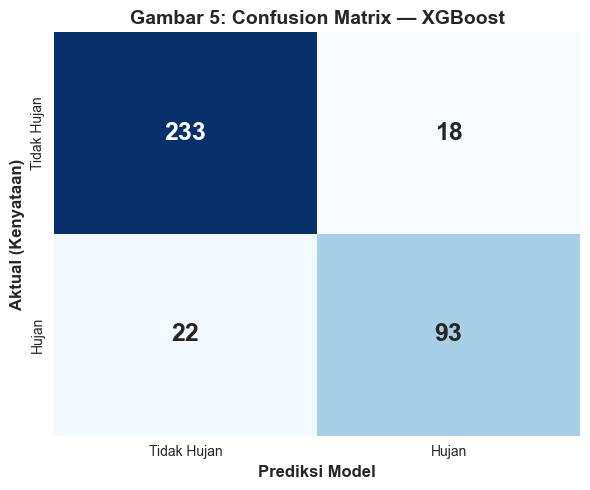

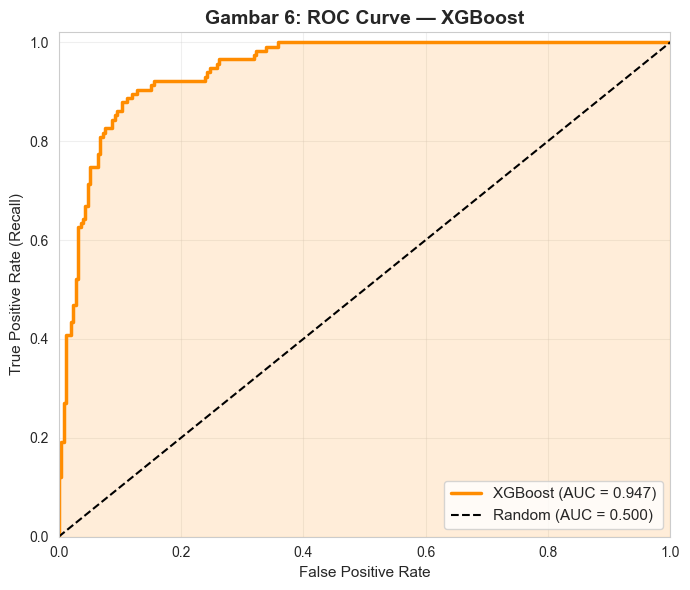

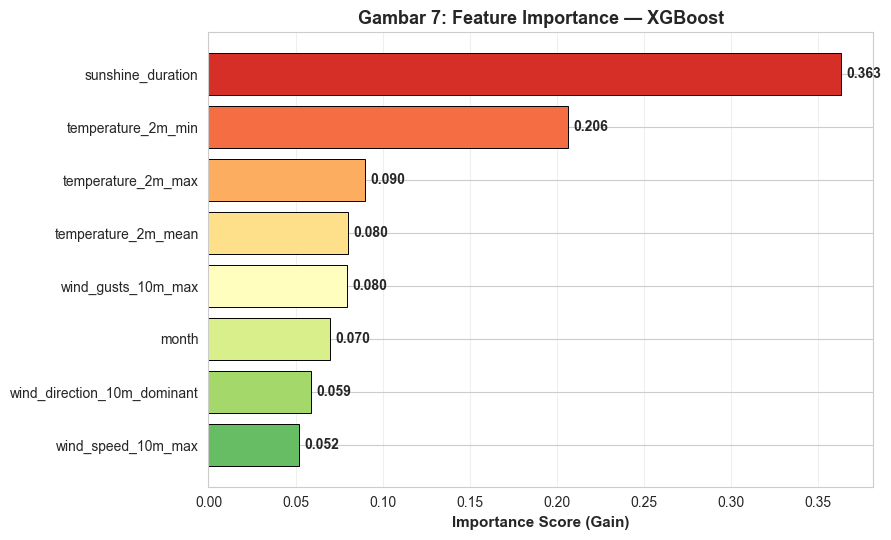

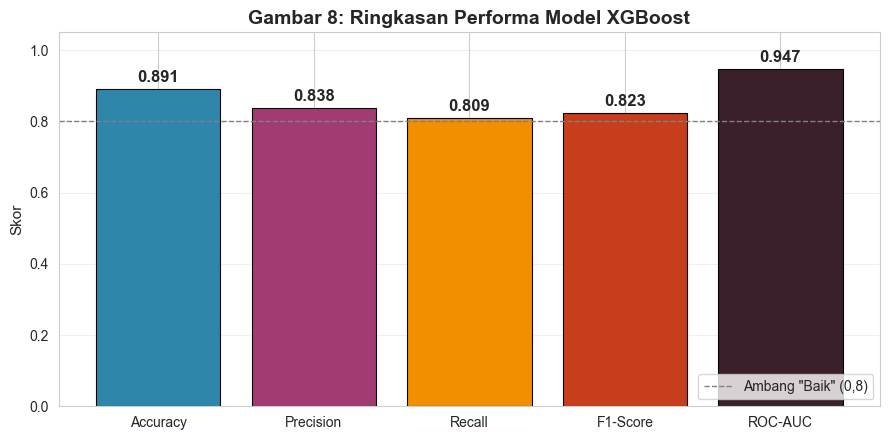

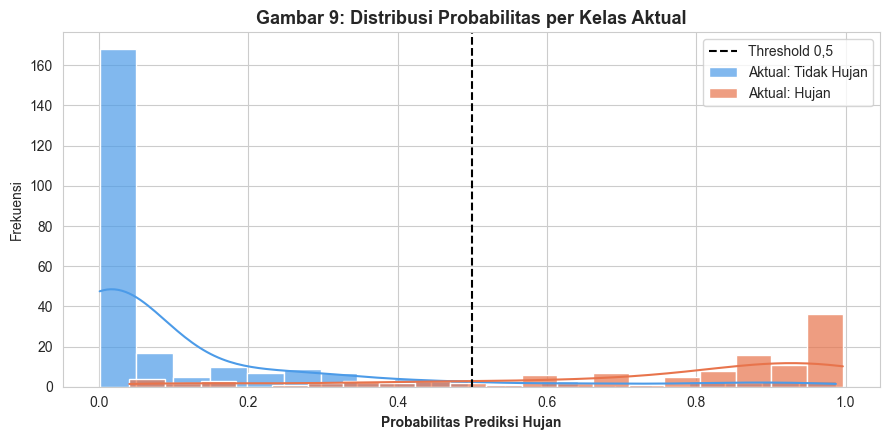


✅ Semua visualisasi tersimpan di folder output/:
   01_distribusi_fitur.png
   02_proporsi_kelas.png
   03_heatmap_korelasi.png
   04_tren_cuaca.png
   05_confusion_matrix.png
   06_roc_curve.png
   07_feature_importance.png
   08_ringkasan_metrik.png
   09_distribusi_proba.png


In [27]:
# ============================================================
# LANGKAH 6: VISUALISASI HASIL
# ============================================================
from sklearn.metrics import confusion_matrix, roc_curve

# 6.1 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Tidak Hujan","Hujan"],
            yticklabels=["Tidak Hujan","Hujan"],
            annot_kws={"size":18, "fontweight":"bold"}, ax=ax)
ax.set_xlabel("Prediksi Model", fontweight='bold', fontsize=12)
ax.set_ylabel("Aktual (Kenyataan)", fontweight='bold', fontsize=12)
ax.set_title("Gambar 5: Confusion Matrix — XGBoost",
             fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig("output/05_confusion_matrix.png", bbox_inches='tight')
plt.show()

# 6.2 ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2.5,
        label=f'XGBoost (AUC = {auc:.3f})')
ax.plot([0,1], [0,1], 'k--', lw=1.5, label='Random (AUC = 0.500)')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
ax.set_xlabel("False Positive Rate", fontsize=11)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=11)
ax.set_title("Gambar 6: ROC Curve — XGBoost",
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("output/06_roc_curve.png", bbox_inches='tight')
plt.show()

# 6.3 Feature Importance
imp = pd.Series(model.feature_importances_, index=fitur).sort_values()
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(imp)))
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(imp.index, imp.values, color=colors,
               edgecolor='black', linewidth=0.7)
ax.set_xlabel("Importance Score (Gain)", fontsize=11, fontweight='bold')
ax.set_title("Gambar 7: Feature Importance — XGBoost",
             fontsize=13, fontweight='bold')
for b, v in zip(bars, imp.values):
    ax.text(v + 0.003, b.get_y()+b.get_height()/2,
            f"{v:.3f}", va='center', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("output/07_feature_importance.png", bbox_inches='tight')
plt.show()

# 6.4 Ringkasan metrik (bar chart)
metrik = {'Accuracy': acc, 'Precision': prec, 'Recall': rec,
          'F1-Score': f1, 'ROC-AUC': auc}
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#2E86AB','#A23B72','#F18F01','#C73E1D','#3B1F2B']
bars = ax.bar(list(metrik.keys()), list(metrik.values()),
              color=colors, edgecolor='black', linewidth=0.8)
ax.axhline(0.8, color='gray', linestyle='--', lw=1, label='Ambang "Baik" (0,8)')
ax.set_ylim(0, 1.05); ax.set_ylabel("Skor", fontsize=11)
ax.set_title("Gambar 8: Ringkasan Performa Model XGBoost",
             fontsize=14, fontweight='bold')
for b, v in zip(bars, metrik.values()):
    ax.text(b.get_x()+b.get_width()/2, v+0.02, f"{v:.3f}",
            ha='center', fontweight='bold', fontsize=12)
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("output/08_ringkasan_metrik.png", bbox_inches='tight')
plt.show()

# 6.5 Distribusi probabilitas prediksi
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(y_proba[y_test==0], bins=20, color='#4C9BE8',
             label='Aktual: Tidak Hujan', alpha=0.7, ax=ax, kde=True)
sns.histplot(y_proba[y_test==1], bins=20, color='#E8744C',
             label='Aktual: Hujan', alpha=0.7, ax=ax, kde=True)
ax.axvline(0.5, color='black', linestyle='--', lw=1.5, label='Threshold 0,5')
ax.set_xlabel("Probabilitas Prediksi Hujan", fontweight='bold')
ax.set_ylabel("Frekuensi")
ax.set_title("Gambar 9: Distribusi Probabilitas per Kelas Aktual",
             fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig("output/09_distribusi_proba.png", bbox_inches='tight')
plt.show()

print("\n✅ Semua visualisasi tersimpan di folder output/:")
print("   01_distribusi_fitur.png")
print("   02_proporsi_kelas.png")
print("   03_heatmap_korelasi.png")
print("   04_tren_cuaca.png")
print("   05_confusion_matrix.png")
print("   06_roc_curve.png")
print("   07_feature_importance.png")
print("   08_ringkasan_metrik.png")
print("   09_distribusi_proba.png")

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_test_scaled  = scaler.transform(X_test)        # transform SAJA

print(f"Mean  : {np.round(scaler.mean_, 2)}")
print(f"Scale : {np.round(scaler.scale_, 2)}")

Mean  : [2.627000e+01 3.111000e+01 2.249000e+01 1.374000e+01 3.064000e+01
 1.900700e+02 3.310975e+04 6.560000e+00]
Scale : [4.04000e+00 3.94000e+00 4.82000e+00 5.03000e+00 8.97000e+00 1.00790e+02
 9.99328e+03 3.46000e+00]


In [29]:
df_train_norm = pd.DataFrame(X_train_scaled, columns=fitur)
df_train_norm['is_rainy'] = y_train.values
df_train_norm['split']    = 'train'

df_test_norm = pd.DataFrame(X_test_scaled, columns=fitur)
df_test_norm['is_rainy'] = y_test.values
df_test_norm['split']    = 'test'

df_normalized = pd.concat([df_train_norm, df_test_norm], ignore_index=True)
df_normalized.to_csv("Alma_Test1_KlasifikasiXGBoost.csv", index=False)

pd.DataFrame({'fitur': fitur, 'mean': scaler.mean_, 'scale': scaler.scale_}) \
  .to_csv("output/scaler_params.csv", index=False)

print(f"✅ Alma_Test1_KlasifikasiXGBoost.csv disimpan: {df_normalized.shape}")
print(f"✅ output/scaler_params.csv disimpan")
df_normalized.head()

✅ Alma_Test1_KlasifikasiXGBoost.csv disimpan: (1827, 10)
✅ output/scaler_params.csv disimpan


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,month,is_rainy,split
0,-1.873135,-1.525533,-1.864578,-0.762183,-1.208000,1.180032,0.289220,1.571322,0,train
1,0.822487,1.543397,0.396333,0.350472,-0.249470,0.088637,0.199048,-1.030531,0,train
2,-1.131220,-0.764642,-1.325278,-0.921134,-1.208000,1.557060,0.367757,1.282227,0,train
3,0.847218,0.503511,1.039344,-0.046905,-0.528112,0.138246,-0.631694,0.125848,1,train
4,-0.611880,-0.637826,-0.765236,-1.616544,-1.486642,-1.786578,0.649462,-1.319626,0,train
